# Generative AI Applications - Conditional DCGAN on Fashion-MNIST

## How this notebook is organised

1. Imports.
2. Task definition and model choice.
3. Dataset: description, loading, and inspection.
4. Model: conditional DCGAN.
5. Training.

> TODO: extend this index as the sections land.


## 1. Imports


In [1]:
# imports, the one disclosed seed (SEED=42), device probe, and figures/ for saved figures
import hashlib
import math
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import DataLoader
import torchvision.datasets as datasets
import torchvision.transforms as transforms

import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__}, CUDA available: {torch.cuda.is_available()}, device: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)

torch 2.11.0+cu128, CUDA available: True, device: cuda
GPU: NVIDIA GeForce RTX 4080 Laptop GPU


## 2. Task definition and model choice


**Task:**
- **Goal:** train a small generative model that produces new images.
- **Data:** the Fashion-MNIST dataset (Xiao et al., 2017).
- **Method:** the model learns the dataset distribution, then generates new images from random noise.
- **Dataset section:** the dataset facts and the loading policy are in the dataset section below, starting next.


**Model:**
- **Type:** a conditional DCGAN.
- **Backbone:** Radford et al. (2016).
- **Conditioning:** the class label, in the way of Mirza and Osindero (2014).
- **Training improvement:** label smoothing, with real labels at `0.9` and fake labels at `0.1`.
- **Variant chosen:** the two-sided form that Salimans et al. (2016) recommend.
- **Effect:** it keeps the discriminator from becoming overconfident.


**Why the conditional variant:**
- **Classes:** Fashion-MNIST has `10` recognizable product categories, from T-shirt/top to Ankle boot.
- **Experiment:** conditioning the generator on the class label turns "generate a shirt" into a controlled experiment.
- **Control:** one fixed noise vector holds the other inputs constant.
- **Reading:** the label is then the only variable per column, so the per-class grids show what the condition controls and where generation fails.
- **Alternative:** an unconditional GAN or a VAE would make this evaluation weaker, a point the summary returns to.


**Evaluation:**
- **Qualitative:** the qualitative evaluation later in this notebook reads the outputs as images. The items are the per-class grids, the real-vs-generated pairs, and the failure strip.
- **Quantitative:** the quantitative evaluation later in this notebook measures a per-class agreement score, a feature-space Frechet distance, and an intra-class diversity measure.
- **Reader:** every measurement passes through one separately trained evaluation classifier, independent of the generator in architecture, parameters, and optimization, and trained on the same real data (the practice of Odena et al., 2017).
- **Feature space:** the distance and the diversity readings use the classifier's `128`-dimensional penultimate features (Heusel et al., 2017).
- **Protocol:** a generation-protocol experiment measures why generated images run in eval mode.
- **Caveat:** the measurements share one feature space, and therefore its biases. Each metric's justification is stated where it is introduced.


## 3. Dataset: description, loading, and inspection


**Dataset:**
- **Name:** Fashion-MNIST, from Zalando Research.
- **Images:** `70,000` grayscale `28x28`.
- **Classes:** `10`, with `7,000` images per class.
- **Format:** renderings derived from the retailer's product photographs, published in the IDX format.
- **Documentation:** `DATASET.md` records the access policy, the license, and the archive checksums.


**Load and normalisation policy:**
- **Source:** the repository's `data/` directory.
- **Offline-first:** `download=False` runs first.
- **Fallback:** `download=True` runs only if the local copy is absent, from the same public archives.
- **Integrity:** `DATASET.md` records provenance, license, and integrity values.
- **Normalisation:** images scaled to the `[-1, 1]` range, matching the generator's `Tanh` output (Radford et al., 2016).


### Load Fashion-MNIST (offline-first) and print the split counts


In [2]:
# offline-first load and printed per-class balance; download=True is only the documented fallback
DATA_ROOT = Path("data")

tf = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,)),
    ]
)

try:
    train_data = datasets.FashionMNIST(DATA_ROOT, train=True, download=False, transform=tf)
    test_data = datasets.FashionMNIST(DATA_ROOT, train=False, download=False, transform=tf)
except Exception as exc:
    print(f"Offline load failed ({exc}); falling back to download=True")
    train_data = datasets.FashionMNIST(DATA_ROOT, train=True, download=True, transform=tf)
    test_data = datasets.FashionMNIST(DATA_ROOT, train=False, download=True, transform=tf)

CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

labels = np.asarray(train_data.targets)
counts = np.bincount(labels, minlength=10)
print("training images:", len(train_data), "test images:", len(test_data))
for i, name in enumerate(CLASSES):
    print(f"  class {i} {name:<12} {counts[i]:5d} images")
assert counts.min() == counts.max(), "per-class count imbalance: " + str(counts)


training images: 60000 test images: 10000
  class 0 T-shirt/top   6000 images
  class 1 Trouser       6000 images
  class 2 Pullover      6000 images
  class 3 Dress         6000 images
  class 4 Coat          6000 images
  class 5 Sandal        6000 images
  class 6 Shirt         6000 images
  class 7 Sneaker       6000 images
  class 8 Bag           6000 images
  class 9 Ankle boot    6000 images


### Verify the documented checksums before any training


In [3]:
# Dataset integrity: verify the checksums documented in DATASET.md at load time,
# before any training depends on this data
# Scope note: these hashes establish the provenance and integrity of the four compressed download archives
# as distributed
# torchvision consumes the extracted IDX files; the extracted files are not re-hashed here

# expected values (SHA256 and byte size), from DATASET.md
DATASET_SHA256 = {
    "train-images-idx3-ubyte.gz": "3aede38d61863908ad78613f6a32ed271626dd12800ba2636569512369268a84",
    "train-labels-idx1-ubyte.gz": "a04f17134ac03560a47e3764e11b92fc97de4d1bfaf8ba1a3aa29af54cc90845",
    "t10k-images-idx3-ubyte.gz": "346e55b948d973a97e58d2351dde16a484bd415d4595297633bb08f03db6a073",
    "t10k-labels-idx1-ubyte.gz": "67da17c76eaffca5446c3361aaab5c3cd6d1c2608764d35dfb1850b086bf8dd5",
}

DATASET_SIZES = {
    "train-images-idx3-ubyte.gz": 26421880,
    "train-labels-idx1-ubyte.gz": 29515,
    "t10k-images-idx3-ubyte.gz": 4422102,
    "t10k-labels-idx1-ubyte.gz": 5148,
}

raw_dir = DATA_ROOT / "FashionMNIST" / "raw"
for name, expected_hash in DATASET_SHA256.items():
    archive = raw_dir / name
    digest = hashlib.sha256(archive.read_bytes()).hexdigest()
    assert digest == expected_hash, f"SHA256 mismatch for {name}: {digest}"
    assert archive.stat().st_size == DATASET_SIZES[name], f"size mismatch for {name}"
print(f"dataset integrity: {len(DATASET_SHA256)}/4 archives match DATASET.md (SHA256 + size)")


dataset integrity: 4/4 archives match DATASET.md (SHA256 + size)


### Real reference samples, one per class (reused by the figure cells below)


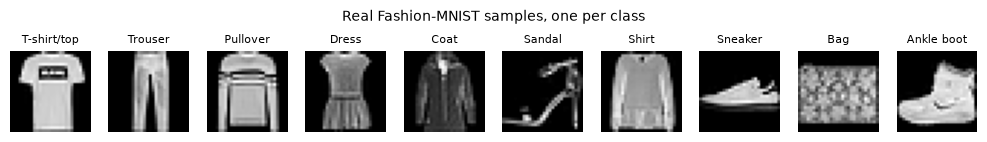

In [4]:
# Real reference samples, one per class, in train-set order
# "real" rows reused for the real-vs-generated comparison

shown = torch.full((10,), -1, dtype=torch.long)
real_by_class = torch.zeros(10, 1, 28, 28)
idx = 0
for im, lab in train_data:
    if shown[lab] == -1:
        shown[lab] = idx
        real_by_class[lab] = im
        if int(shown.min()) >= 0:
            break
    idx += 1

fig = plt.figure(figsize=(10, 1.4))
for i in range(10):
    ax = fig.add_subplot(1, 10, i + 1)
    ax.imshow((real_by_class[i, 0] * 0.5 + 0.5).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASSES[i], fontsize=8)
    ax.axis("off")
fig.suptitle("Real Fashion-MNIST samples, one per class", fontsize=10)
fig.tight_layout()
fig.savefig(FIGDIR / "fig0-real-samples.png", bbox_inches="tight", dpi=110)
plt.show()


## 4. Model: conditional DCGAN

**Generator:**
- **Input:** a `100`-dimensional noise vector and a class label.
- **Conditioning:** the label goes through an Embedding layer and is concatenated with the noise.
- **Projection:** a dense Linear layer to a `7 x 7 x 256` volume.
- **Upsampling:** two `ConvTranspose2d` layers with stride `2`, to `14 x 14` and then `28 x 28`.
- **Output:** a final stride-1 `ConvTranspose2d` maps the remaining `64` channels to the single image channel, through a `Tanh` layer that lands pixels in `[-1, 1]` (Radford et al., 2016).

**BatchNorm placement:**
- **Generator:** after the dense projection and the two upsampling layers.
- **Exception:** the output layer is the documented exception, per the DCGAN guidelines.
- **Discriminator:** on the second downsampling convolution.
- **Activations:** `LeakyReLU(0.2)` in the discriminator layers, ReLU in the generator's hidden layers.

**Label conditioning in the discriminator:**
- **Channel:** the class condition enters as an extra input channel.
- **Map:** the label's Embedding output is reshaped to a `28 x 28` map and concatenated with the image.
- **Binding:** the convolution stack judges the image and its label together from the first layer, which binds the label to the content during the adversarial game.
- **Head:** the conv features are scored by an explicit dense head, `Linear(128 * 7 * 7, 1)`.
- **Checkability:** the layers named here are the layers of this code, so the description is checkable against the implementation.


### Define the generator and discriminator, then verify tensor shapes


In [5]:

# Generator and Discriminator definitions for conditional GAN on Fashion-MNIST
NZ = 100          # noise dimension
N_CLASSES = 10
EMB = 16          # label embedding dimension
G_BASE = 256      # generator base channels


class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_embedding = nn.Embedding(N_CLASSES, EMB)
        self.fc = nn.Linear(NZ + EMB, 7 * 7 * G_BASE)
        self.net = nn.Sequential(
            nn.BatchNorm1d(7 * 7 * G_BASE),
            nn.ReLU(True),
            nn.Unflatten(1, (G_BASE, 7, 7)),
            nn.ConvTranspose2d(G_BASE, 128, kernel_size=4, stride=2, padding=1),  # 7x7 -> 14x14
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),      # 14x14 -> 28x28
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 1, kernel_size=3, stride=1, padding=1),        # 28x28
            nn.Tanh(),
        )

    def forward(self, z, labels):
        y = self.label_embedding(labels)
        return self.net(self.fc(torch.cat([z, y], dim=1)))


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.label_map = nn.Embedding(N_CLASSES, 28 * 28)   # label rendered as an image channel
        self.features = nn.Sequential(
            nn.Conv2d(2, 64, kernel_size=4, stride=2, padding=1),   # 28x28 -> 14x14 (image + label map)
            nn.LeakyReLU(0.2, True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1), # 14x14 -> 7x7
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, True),
            nn.Flatten(),
        )
        self.head = nn.Linear(128 * 7 * 7, 1)  # the explicit dense output head

    def forward(self, imgs, labels):
        ymap = self.label_map(labels).view(-1, 1, 28, 28)
        return self.head(self.features(torch.cat([imgs, ymap], dim=1)))


G = Generator().to(DEVICE)
D = Discriminator().to(DEVICE)

# Tensor-shape verification: shapes produced by G and D
# Eval mode, so the diagnostic forward passes do not touch the BatchNorm running statistics
G.eval()
D.eval()
z_probe = torch.randn(4, NZ, device=DEVICE)
y_probe = torch.randint(0, N_CLASSES, (4,), device=DEVICE)
img_probe = torch.randn(4, 1, 28, 28, device=DEVICE)
with torch.no_grad():
    g_out = G(z_probe, y_probe)
    d_out = D(img_probe, y_probe)
G.train()
D.train()
assert g_out.shape == (4, 1, 28, 28), g_out.shape
assert d_out.shape == (4, 1), d_out.shape
print("G(z, y) ->", tuple(g_out.shape), "D(img, y) ->", tuple(d_out.shape))
n_g = sum(p.numel() for p in G.parameters())
n_d = sum(p.numel() for p in D.parameters())
print(f"trainable parameters: generator {n_g:,}, discriminator {n_d:,}")


G(z, y) -> (4, 1, 28, 28) D(img, y) -> (4, 1)
trainable parameters: generator 2,149,409, discriminator 147,681


## 5. Training

**Adversarial game:**
- **Update:** the standard two-step update of the original GAN paper and the DCGAN paper.
- **Optimizers:** both Adam, with `lr=2e-4` and betas `(0.5, 0.999)` (Radford et al., 2016).
- **Loss:** BCEWithLogitsLoss on raw logits.

**The one training improvement, label smoothing:**
- **Targets:** `0.9` for real, `0.1` for fake.
- **Variant:** two-sided, against the one-sided smoothing in Salimans et al. (2016).
- **Reference:** their section 3.4 smooths only the positive labels and leaves the negative targets at `0`. This notebook smooths both sides.
- **Effect:** the smoothed targets keep the discriminator from becoming overconfident and preserve useful gradients for the generator (Salimans et al., 2016).
- **Generator target:** the generator still trains against the hard real target, as in Salimans et al. (2016).

**Chance baselines:**
- **Scale:** the two losses sit on different scales, so both baselines are stated.
- **Discriminator:** about `2*ln(2) = 1.386`, the sum of two binary terms.
- **Generator:** about `ln(2) = 0.693`.
- **Figure:** the loss figure below draws both baselines.

**Budget:**
- **Epochs:** `50`, at a batch size of `128`.
- **Seed:** one fixed `SEED = 42`, set in the setup cell.
- **Logs:** the discriminator loss, the generator loss, and the mean logits, on every batch.
- **Snapshots:** captured with a fixed noise batch, drawn from the same seeding, so a full notebook run reproduces them.
- **Reading:** the sample-progression figure therefore shows only the model's change over time.


### Train 50 epochs with label smoothing; record losses and fixed-noise snapshots


In [ ]:
# Training configuration and loop for conditional GAN on Fashion-MNIST
EPOCHS = 50
BATCH_SIZE = 128
LR = 2e-4
REAL_TARGET = 0.9   # label smoothing (a two-sided variant of Salimans et al., 2016)
FAKE_TARGET = 0.1
D_CHANCE = 2 * math.log(2)   # ~1.386, sum of two BCE terms
G_CHANCE = math.log(2)       # ~0.693, one BCE term

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
criterion = nn.BCEWithLogitsLoss()
optG = optim.Adam(G.parameters(), lr=LR, betas=(0.5, 0.999))
optD = optim.Adam(D.parameters(), lr=LR, betas=(0.5, 0.999))

# Fixed evaluation inputs (drawn from the setup cell's seeding; a full notebook run reproduces them)
n_snap = 64  # batch of 64 keeps train-mode BatchNorm statistics representative
fixed_z = torch.randn(n_snap, NZ, device=DEVICE)
fixed_labels = torch.arange(n_snap, device=DEVICE) % N_CLASSES  # 0..9 cycling
SNAP_EPOCHS = {1, 5, 10, 25, 50}
snapshots = {}

d_losses, g_losses, d_logits_real_m, d_logits_fake_m = [], [], [], []

start = time.time()
for epoch in range(1, EPOCHS + 1):
    ep_d, ep_g = [], []
    for imgs, labels in train_loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        bs = imgs.size(0)

        # 1. Discriminator: real toward REAL_TARGET, fake toward FAKE_TARGET
        optD.zero_grad()
        d_real = D(imgs, labels)
        d_logits_real_m.append(float(d_real.mean().detach()))
        loss_real = criterion(d_real, torch.full((bs, 1), REAL_TARGET, device=DEVICE))
        fake_z = torch.randn(bs, NZ, device=DEVICE)
        with torch.no_grad():
            fake_imgs = G(fake_z, labels)
        d_fake = D(fake_imgs, labels)
        d_logits_fake_m.append(float(d_fake.mean().detach()))
        loss_fake = criterion(d_fake, torch.full((bs, 1), FAKE_TARGET, device=DEVICE))
        d_loss = loss_real + loss_fake
        d_loss.backward()
        optD.step()

        # 2. Generator: fakes judged against hard real targets
        optG.zero_grad()
        g_z = torch.randn(bs, NZ, device=DEVICE)
        g_logits = D(G(g_z, labels), labels)
        g_loss = criterion(g_logits, torch.ones(bs, 1, device=DEVICE))
        g_loss.backward()
        optG.step()

        ep_d.append(float(d_loss.detach()))
        ep_g.append(float(g_loss.detach()))

    d_losses.append(float(np.mean(ep_d)))
    g_losses.append(float(np.mean(ep_g)))
    if epoch in SNAP_EPOCHS:
        # Diagnostics must not perturb training: eval mode uses the running
        # statistics as they are (train mode would update them again here).
        G.eval()
        with torch.no_grad():
            snapshots[epoch] = G(fixed_z, fixed_labels).detach().cpu()
        G.train()
    print(f"epoch {epoch:2d}  D {d_losses[-1]:.3f}  G {g_losses[-1]:.3f}")

elapsed = time.time() - start
print(f"total training time: {elapsed:.1f} s ({elapsed / 60:.1f} min), {elapsed / EPOCHS:.1f} s/epoch")


epoch  1  D 0.814  G 2.019


epoch  2  D 1.103  G 1.217


epoch  3  D 1.074  G 1.206


epoch  4  D 1.132  G 1.140


epoch  5  D 1.202  G 1.026


epoch  6  D 1.240  G 0.966


... (40 outputs left out)

epoch 47  D 1.389  G 0.723


epoch 48  D 1.390  G 0.723


epoch 49  D 1.390  G 0.723


epoch 50  D 1.390  G 0.723
total training time: 435.2 s (7.3 min), 8.7 s/epoch
